In [3]:
from regions import Regions
import astropy.units as u

regs = Regions.read("/home/thsu/FRB_population/MeerKat_beams/tiling_region.reg", format="ds9")
for r in regs:
    print(type(r).__name__, r)       # check whether the file has more than one region

reg = regs[0]
print(reg.center)
print("width :", reg.width.to(u.deg))
print("height:", reg.height.to(u.deg))
print("radius (if circular):", (reg.width/2).to(u.deg))
print("angle :", reg.angle)

EllipseSkyRegion Region: EllipseSkyRegion
center: <SkyCoord (FK5: equinox=J2000.000): (ra, dec) in deg
    (100.196833, -30.713333)>
width: 78.46902 arcsec
height: 75.216728 arcsec
angle: 38.97322 deg
EllipseSkyRegion Region: EllipseSkyRegion
center: <SkyCoord (FK5: equinox=J2000.000): (ra, dec) in deg
    (100.177126, -30.699622)>
width: 78.46902 arcsec
height: 75.216728 arcsec
angle: 38.97322 deg
EllipseSkyRegion Region: EllipseSkyRegion
center: <SkyCoord (FK5: equinox=J2000.000): (ra, dec) in deg
    (100.216547, -30.727041)>
width: 78.46902 arcsec
height: 75.216728 arcsec
angle: 38.97322 deg
EllipseSkyRegion Region: EllipseSkyRegion
center: <SkyCoord (FK5: equinox=J2000.000): (ra, dec) in deg
    (100.157423, -30.685909)>
width: 78.46902 arcsec
height: 75.216728 arcsec
angle: 38.97322 deg
EllipseSkyRegion Region: EllipseSkyRegion
center: <SkyCoord (FK5: equinox=J2000.000): (ra, dec) in deg
    (100.236266, -30.740746)>
width: 78.46902 arcsec
height: 75.216728 arcsec
angle: 38.97322

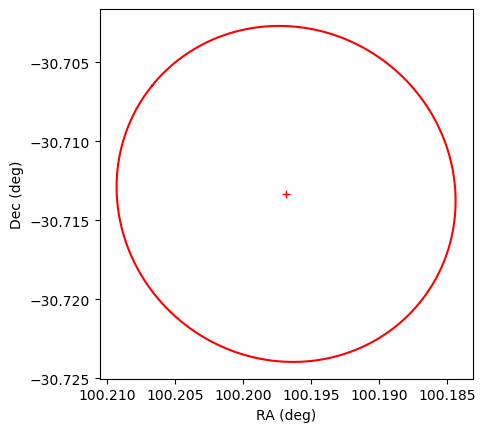

semi-axes: 0.01090 deg, 0.01045 deg


In [6]:
import numpy as np
import matplotlib.pyplot as plt
from regions import Regions
import astropy.units as u
%matplotlib inline
reg = Regions.read("/home/thsu/FRB_population/MeerKat_beams/tiling_region.reg", format="ds9")[0]

c = reg.center
a = (reg.width  / 2).to(u.deg).value    # semi-axis along RA direction
b = (reg.height / 2).to(u.deg).value    # semi-axis along Dec direction
th = reg.angle.to(u.rad).value          # rotation, counter-clockwise

t = np.linspace(0, 2*np.pi, 400)
dx = a*np.cos(t)*np.cos(th) - b*np.sin(t)*np.sin(th)   # offset toward East (deg)
dy = a*np.cos(t)*np.sin(th) + b*np.sin(t)*np.cos(th)   # offset toward North (deg)

ra  = c.ra.deg  + dx/np.cos(c.dec.rad)
dec = c.dec.deg + dy

fig, ax = plt.subplots()
ax.plot(ra, dec, "r-")
ax.plot(c.ra.deg, c.dec.deg, "r+")
ax.invert_xaxis()                        # RA increases to the left
ax.set_aspect(1/np.cos(c.dec.rad))       # keep it undistorted on the sky
ax.set_xlabel("RA (deg)")
ax.set_ylabel("Dec (deg)")
plt.show()

print(f"semi-axes: {a:.5f} deg, {b:.5f} deg")